# Question 3

by Victoria Gemoets-Johnson

***

**How does age impact the relationship between socioeconomic status and the health of an individual across both data sets??**

***

step 1: import libraries and data and clean out blank rows 

In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [23]:
pvd = pd.read_excel('data/pvdstudy.xlsx')
pvd

,L.P.,Participant code,Pregnancy meeting,Stress scale,Stress1,Stress2,Stress3,Stress4,Stress5,Stress6,...,PVD9.1,PVD10.1,PVD11.1,PVD12.1,PVD13.1,PVD14.1,PVD15.1,Infectability sum,Germ aversion Sum,Total Sum
0,1,1,NaN,NaN,2,2,3,2,1,3,...,1,1,7,6,3,6,4,14,22,36
1,2,2,NaN,NaN,3,4,4,2,3,4,...,2,6,6,3,1,3,2,34,30,64
2,3,3,NaN,NaN,1,1,1,1,1,1,...,1,1,7,1,1,7,7,13,28,41
3,4,4,NaN,NaN,4,1,4,0,1,2,...,1,1,3,4,3,4,1,17,22,39
4,5,5,NaN,NaN,3,1,4,2,2,4,...,3,4,1,3,7,4,2,29,33,62
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,196,217,NaN,NaN,1,1,2,1,1,3,...,1,1,5,6,3,6,1,14,19,33
196,197,218,NaN,NaN,1,0,2,2,2,3,...,4,4,6,4,3,4,3,29,34,63
197,198,219,NaN,NaN,2,2,2,1,1,3,...,3,1,6,6,5,5,1,14,23,37
198,199,220,NaN,NaN,0,0,0,0,0,0,...,1,4,5,4,2,4,2,28,32,60


In [24]:
hrsn = pd.read_csv('data/hrsnstudy.csv')
hrsn

,study_id,delivery_type,survey_language,year_del,month_postpartum,age,hispanic,raceth_grp,birth_country,insurance,...,count_total_need_plus_tp2,flag_any_plus_tp2,received,daycount,lastday,htn,pp_visit_6_wks,pcp,ed_or_hosp,random_order
0,1,C/S,Haitian Creole,2022,23,44,2,2,2,1,...,3,1,1,3.0,26.0,No,1,0,0,0.007992
1,2,C/S,English,2022,24,33,2,2,1,1,...,2,1,0,NaN,NaN,NaN,0,0,0,0.014961
2,3,C/S,Spanish,2022,17,22,1,1,2,1,...,2,1,1,14.0,40.0,Stage 1,1,1,0,0.017957
3,4,C/S,Haitian Creole,2023,6,40,2,2,2,1,...,2,1,0,NaN,NaN,NaN,1,0,0,0.018918
4,5,Vag,English,2023,10,35,2,2,1,1,...,2,1,1,3.0,25.0,Stage 1,1,1,0,0.030806
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
80,81,C/S,English,2022,22,31,2,4,2,2,...,0,0,1,33.0,41.0,Stage 2+,1,0,0,0.959896
81,82,Vag,English,2023,14,33,2,3,1,2,...,0,0,0,NaN,NaN,NaN,1,0,0,0.975410
82,83,Vag,English,2022,22,40,1,1,1,1,...,1,1,1,1.0,10.0,NaN,1,0,1,0.984596
83,84,Vag,Haitian Creole,2022,14,33,2,2,2,1,...,4,1,1,37.0,42.0,Stage 2+,1,1,0,0.985341


In [25]:
pvd_cleaned = pvd.dropna(axis=1, how='any')
pvd_cleaned.shape
pvd_cleaned.columns.tolist()

['L.P.',
 'Participant code',
 'Stress1',
 'Stress2',
 'Stress3',
 'Stress4',
 'Stress5',
 'Stress6',
 'Stress7',
 'Stress8',
 'Stress9',
 'Stress10',
 'SUM (0-40)',
 'PVD1',
 'PVD2',
 'PVD3',
 'PVD4',
 'PVD5',
 'PVD6',
 'PVD7',
 'PVD8',
 'PVD9',
 'PVD10',
 'PVD11',
 'PVD12',
 'PVD13',
 'PVD14',
 'PVD15',
 'Infectability SUM',
 'Germ SUM',
 'Total SUM',
 'Pregnancy week',
 'Age',
 'Weight before pregnancy',
 'Current weight',
 'Height',
 'Partner weight',
 'Partner age',
 'Partner height',
 'Asthma',
 'Allergies',
 'Epilepsy',
 'Heart condition',
 'Diabetes',
 'Thyroid problems',
 'Hypertension',
 'Coronary heart disease',
 'Anaemia',
 'Endometriosis',
 'Other diseases',
 'Hormonal problems',
 'Education',
 'Income (1 - below 600, 2 - 600 - 1000, 3- 1000 - 1500, 4 - 1500 - 2000, 5 - 2000 - 3000, 6 - 3000 - 4000, 7 - 4000 - 6000, 8 - over 6000 PLN)',
 'SES self-assessment (1very poor to 7very good)',
 'Relationship status (1single, 2cohabiting, 3married)',
 'Relationship with a biologic

In [26]:
hrsn_cleaned = hrsn.dropna(axis=1, how='any')
hrsn_cleaned.shape
hrsn_cleaned.columns.tolist()

['study_id',
 'delivery_type',
 'survey_language',
 'year_del',
 'month_postpartum',
 'age',
 'hispanic',
 'raceth_grp',
 'birth_country',
 'insurance',
 'smoking_status',
 'p',
 'g',
 'count_total_need_plus_tp1',
 'flag_any_plus_tp1',
 'living_need_yes_plus_tp2',
 'living_need_yes_lookback_tp2',
 'count_total_need_plus_tp2',
 'flag_any_plus_tp2',
 'received',
 'pp_visit_6_wks',
 'pcp',
 'ed_or_hosp',
 'random_order']

***

step 2: clean the data and pick out the columns I need and will actually use
pvd will use columns: 
Age
Education
Income 
SES self-assessment
Health
Disease severity 
SUM (0-40) (stress) 
pre-pregnancy BMI

hrsn will use columns:
age
count_total_need_plus_tp1/tp2 
insurance
ed_or_hosp
pcp
pp_visit_6_wks 
htn

step 3: make a first look heatmap to show the correlation for each data set bewteen pvd's age SES status and health relations and  hrsn's age SES status and health relations and 

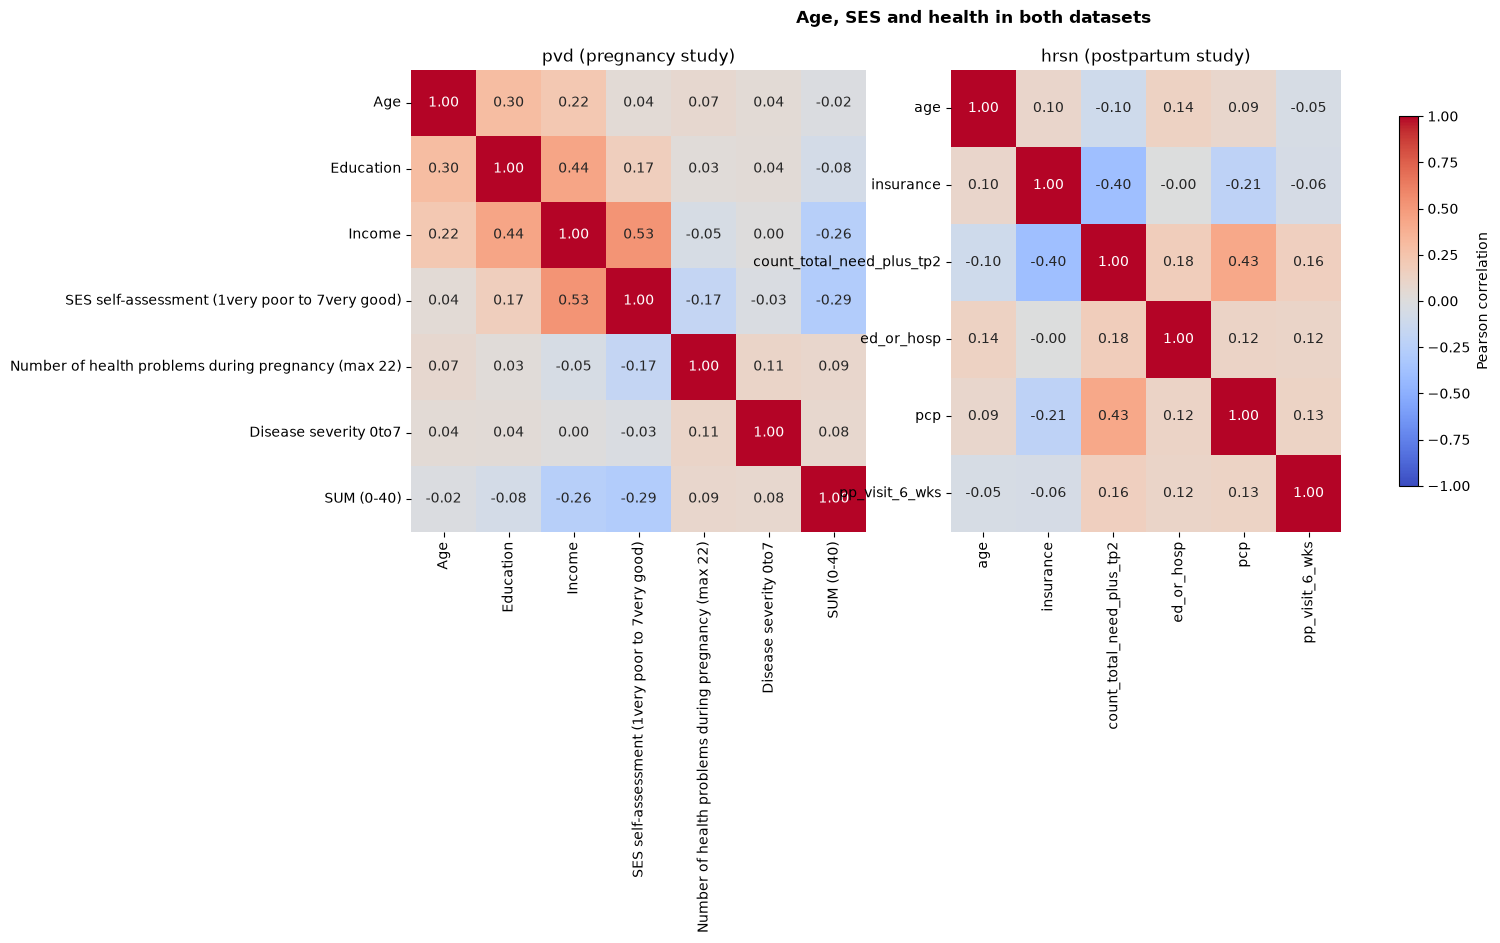

In [35]:
pvd_cols = ['Age','Education','Income','SES self-assessment (1very poor to 7very good)','Number of health problems during pregnancy (max 22)','Disease severity 0to7','SUM (0-40)',]

pvd = pvd.rename(columns={
    'Income (1 - below 600, 2 - 600 - 1000, 3- 1000 - 1500, 4 - 1500 - 2000, 5 - 2000 - 3000, 6 - 3000 - 4000, 7 - 4000 - 6000, 8 - over 6000 PLN)': 'Income'})

hrsn_cols = ['age', 'insurance', 'count_total_need_plus_tp2', 'ed_or_hosp', 'pcp', 'pp_visit_6_wks']

# correlation
pvd_cols = pvd[pvd_cols].apply(pd.to_numeric, errors='coerce')
pvd_corr = pvd_cols.corr()

hrsn_cols = hrsn[hrsn_cols].apply(pd.to_numeric, errors='coerce')
hrsn_corr = hrsn_cols.corr()

# heat map
fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={'width_ratios': [7, 6]})
for ax, corr, title in zip(axes, [pvd_corr, hrsn_corr], ['pvd (pregnancy study)', 'hrsn (postpartum study)']):
    sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=ax, cbar=False)
    ax.set_title(title)
fig.colorbar(axes[1].collections[0], ax=axes, label='Pearson correlation', shrink=0.8)
fig.suptitle('Age, SES and health in both datasets', fontweight='bold')
plt.show()

Based on this heat map I can tell how the relationship between age, socioeconomic status, and health across the two datasets interacts and if it would even be useful to look at.

In PVD, I will examine whether participants with lower self-assessed SES tend to report greater disease severity and whether this pattern appears different across ages. In HRSN, I will examine how social needs vary with age and whether the pattern differs across insurance categories. These also give me an idea of what categories to utilize when forming an equation to combine columns to form a new one.

***

**FULL PLAN for making a product to turn in**

### Hypothesis

I hypothesize that lower SES will be associated with worse health outcomes and that this relationship will be stronger among older participants than younger participants.

### Analysis Plan

**1. Prepare and describe the data.** I will select relevant variables, inspect missingness and coding, check for implausible values, and calculate descriptive statistics for age, SES, and health outcomes. I will report the number of participants available for each analysis.

**2. Define SES and health separately for each dataset.** In PVD, I will examine education, income, and self-assessed SES as socioeconomic indicators, with disease severity and other relevant health measures as outcomes. In HRSN, I will examine documented socioeconomic indicators, such as insurance and social needs, alongside available measures of postpartum health and healthcare use. I will verify variable definitions before combining or recoding them.

**3. Explore the relationships.** I will use scatterplots, grouped plots, and descriptive statistics to examine how SES and health vary with age. These figures will help identify patterns, skewed distributions, and potential outliers.

**4. Test whether age changes the SES–health relationship.** Where the variables and sample size permit, I will fit a model containing SES, age, and an SES-by-age interaction. For a continuous health outcome, I will consider linear regression; for a binary outcome, I will consider logistic regression; and for a count outcome, I will consider an appropriate count model. I will check the assumptions of the chosen model and interpret the interaction rather than relying only on separate correlations.

**5. Check robustness.** I will examine whether conclusions change when individual SES indicators or alternative health outcomes are used. I will consider relevant covariates only when their definitions, completeness, and sample size support their inclusion. I will also report uncertainty and avoid interpreting small or unstable differences as definitive evidence.

**6. Compare the datasets.** I will compare the direction and general consistency of the patterns across PVD and HRSN, while recognizing that the datasets measure different populations, socioeconomic conditions, and health outcomes. I will not assume that their measures are directly interchangeable.

### Expected Outcomes in Both Directions

**If the hypothesis is supported:** I expect lower SES to be associated with worse health, with a stronger association at older ages. This would be consistent with age modifying the relationship between SES and health in the studied samples. I would still consider uncertainty, alternative explanations, and the possibility that the pattern differs between datasets.

**If the hypothesis is not supported:** The SES–health relationship may be similar across age groups, weaker than expected, absent, or different between datasets. This would suggest that the proposed age-related pattern is not clearly supported by these data. A lack of clear evidence would not necessarily establish that age has no influence, especially given the relatively small samples and limitations in measurement.

### Limitations

Both datasets have limited sample sizes, and their measures of SES and health are not identical. Missing data, self-reported measures, possible confounding variables, and differences between the study populations may affect the results. Observational associations cannot establish causation. Any conclusions will therefore be limited to the available samples and measures.

I hypothesize that lower SES will be associated with worse health outcomes and that this relationship will be stronger among older participants than younger participants. To investigate this, I will first prepare and describe the data by examining relevant variables, missing values, variable types, and descriptive statistics for age, SES, and health outcomes. I will then define SES and health separately for each dataset, using indicators such as education, income, self-assessed SES, disease severity, social needs, and postpartum health measures where available. For now, heat maps will give an overview of how age, SES and health outcomes relate. In this heatmap above, I can tell how the relationship between age, socioeconomic status, and health across the two datasets interacts and if it would even be useful to look at I will also utilize other plots like scatter plots and violin plots to make more observations of these connections and namely to examine how SES and health vary across age groups before testing whether age changes the relationship between SES and health. I will also examine whether the findings change when using different SES indicators or health outcomes and compare the general patterns across the two datasets while accounting for differences in their populations and measurements.

If my hypothesis is supported, I expect to find that lower SES is associated with worse health outcomes and that this association is stronger among older participants. This would suggest that age may influence the relationship between SES and health in these samples. However, if my hypothesis is not supported, the relationship may be similar across age groups, weaker than expected, absent, or just plain different between the two datasets. I am also keeping in mind the smaller sample sizes, missing data and self-reported measures for this as well.